# 15강 실습: 표준국어대사전 형용사의 음절과 받침

14·15강은 임건수(2025)를 다시 해 보는 두 강의다. 논문은 표준국어대사전에서 형용사 후보 목록('어근+하다'를 뺀 2,631개 → 동모음 탈락을 뺀 1,008개)을 만들어 메신저 말뭉치에서 어미 없이 쓰인 어간 62개('부럽', '귀엽')를 찾았다. 그리고 그 62개에 2음절(56.5%)과 끝 받침 'ㅂ'(64.9%)이 많은 까닭을 이렇게 설명했다.

- 표 3 아래(198쪽): "2음절의 어간이 빈도가 높은 이유는 형용사에서 2음절이 많기 때문으로 보인다."
- 표 4 아래(199쪽): "종성 'ㅂ'가 높은 빈도로 나타나는 이유는 'ㅂ'가 형용사 어간의 끝소리로 흔히 나타나는 음운적 특성이기 때문일 것이다."

둘 다 사전의 형용사 전체에 대한 말이라 사전을 세어 확인할 수 있다. 사전에서 2음절과 'ㅂ'이 원래 몇 %인지, 곧 **기준값**을 알아야 56.5%와 64.9%가 많은지 말할 수 있다.

> 임건수(2025), 매체 언어에서 형용사 어간의 자립적 사용 양상 연구, 《한국어학》 107, 183–208. https://doi.org/10.20405/kl.2025.05.107.183

**오늘 할 것**

1. 14강의 표에서 동형어 번호를 떼고 논문의 후보 목록을 다시 만든다.
2. 표제어에서 어간을 얻고, 음절 수와 끝 음절의 받침을 센다(9강의 `decompose`).
3. 논문의 표 2를 옮겨 적고, 표 3·4를 사전의 기준값과 나란히 놓는다.

**시작하기 전에**

- 이 노트북은 저장소 **맨 위**(`/workspaces/LDS2026`)에 두어야 `data/stdict/…` 경로가 맞는다.
- 14강이 만든 `data/stdict/headwords.csv`(머리줄 하나 + 439,566행)를 쓴다. 없으면 14강의 사전 준비(zip 올리기, 압축 풀기)를 다시 하고 `14-xml.ipynb`를 [Run All]로 돌린다.
- 사전은 2026년 10월 12일에 받은 버전이다. 이용 조건은 크리에이티브 커먼즈 저작자표시-동일조건변경허락 2.0 대한민국이다. CSV는 `data/` 아래라 커밋되지 않는다.
- 커밋하기 전에는 [Restart] 후 [Run All]로 위에서 아래까지 한 번에 돌려 본다.

## 0. 준비

7강의 pandas와 seaborn, matplotlib을 불러온다. `font='NanumGothic'`은 10강에서 설치한 나눔고딕으로 그림의 한글을 찍는다(12강과 같다). 오늘은 XML을 읽지 않는다.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid', font='NanumGothic')

## 1. 2,631 다시 만들기

14강 마지막 셀의 셈을 다시 한다.

- `~hada`: `True`와 `False`를 뒤집는다(10강). '-하다'로 끝나지 **않는** 행이다.

남은 5,653행은 논문의 2,631개보다 두 배 넘게 많다. 무엇이 남았는지 들여다본다.

In [2]:
headwords = pd.read_csv('data/stdict/headwords.csv')
adj = headwords[headwords['pos'] == '형용사']
print(len(adj))
hada = adj['word'].str.endswith('-하다')
print(hada.sum(), (~hada).sum())

13400
7747 5653


- `str[-1]`: 문자열마다 마지막 글자. Python의 `w[-1]`을 열 전체에 한다.

형용사인데 '다'로 끝나지 않는 표제어가 3,123행이다. 끝이 숫자다.

In [3]:
rest = adj.loc[~hada, 'word']
print(rest.str[-1].value_counts().head(5).to_dict())

{'다': 2530, '2': 1310, '1': 1283, '3': 334, '4': 112}


14강이 예고한 표제어다. 세 표제어의 뜻풀이(XML의 첫 `definition`)는 이렇다.

- 창연-하다01: 몹시 서운하고 섭섭하다.
- 창연-하다02: 드높아 시원스럽다.
- 창연-하다03: 빛깔이 몹시 푸르다.

셋 다 '어근+하다'인데 끝이 '다'가 아니라 번호라서 `endswith('-하다')`에 걸리지 않았다.

**동형어 번호.** 사전은 글자가 같고 뜻이 다른 표제어(동형어)를 번호로 가른다. XML은 그 번호를 표제어 끝에 두 자리 숫자로 붙여 적었다. '곱다01'은 동사(이익을 보려다가 도리어 손해를 입게 되다), '곱다02'는 형용사(산뜻하고 아름답다), '곱다03'도 형용사(손가락이 얼어서 감각이 없다)다. 번호는 표제어의 일부가 아니다. 끝 글자로 무엇을 가르려면 번호부터 떼야 한다.

In [4]:
print(headwords[headwords['word'].str.startswith('창연-하다')])

        target_code     word word_unit word_type  pos
362949       483736  창연-하다01        단어       혼종어  형용사
362950       319437  창연-하다02        단어       혼종어  형용사
362951       483738  창연-하다03        단어       혼종어  형용사


- `[0-9]+$`: 숫자 한 자리 이상, 그리고 바로 뒤가 끝(4강).
- `regex=True`: 앞의 글을 정규표현식으로 읽으라는 뜻이다. 빠뜨리면 글자 그대로 `[0-9]+$`를 찾아 아무것도 바뀌지 않는다.

`lemma`는 번호를 뗀 표제어다. 고친 것은 `word`가 아니라 새 열이다. 원래 표제어는 그대로 남겨 둔다.

In [5]:
adj['lemma'] = adj['word'].str.replace(r'[0-9]+$', '', regex=True)
print((adj['word'] != adj['lemma']).sum())
print(adj.loc[adj['word'] == '창연-하다02', 'lemma'].tolist())

3123
['창연-하다']


- 2652: 행. 형용사이면서 '-하다'로 끝나지 않는 표제어
- 2652: 표제어 번호. 한 행이 표제어 하나다
- 2626: 번호를 뗀 표제어. '곱다02'와 '곱다03'이 하나가 되어 26이 줄었다

논문의 2,631개에 바짝 다가갔다. 그런데 2,652로 셀까, 2,626으로 셀까?

In [6]:
cand = adj[~adj['lemma'].str.endswith('-하다')]
print(len(cand), cand['target_code'].nunique(), cand['lemma'].nunique())

2652 2652 2626


- `isin(other)`: 품사가 둘 이상인 표제어(14강의 '바삭-하다')를 찾는다.
- `print(*…)`: 열의 값을 빈칸으로 이어 한 줄에 찍는다.

아래 8개는 붙임표가 '하다' 바로 앞에 없어 남았다. 이것도 '어근+하다'일까?

| 무엇을 셌나 | 수 |
|---|---:|
| 형용사 행에서 번호를 떼고 '-하다'로 끝나는 행을 뺀다 | 2,652 |
| 　번호를 뗀 표제어를 하나로 센다 | 2,626 |
| 　다른 품사도 있는 44개를 뺀다 | 2,608 |
| 　그 가운데 '그럴-듯하다' 같은 8개도 뺀다 | 2,600 |
| 논문 | **2,631** |

**버전이 다르면 수도 다르다.** 14강에서 본 대로 사전은 해마다 고쳐진다(2025년 버전 436,145개, 오늘 버전 436,587개). 논문이 쓴 버전과 오늘의 버전은 다를 수 있다. 21개는 2,631의 1%도 안 되는 차이다. 오늘은 2,652행을 후보로 쓴다.

In [7]:
other = headwords.loc[headwords['pos'] != '형용사', 'target_code']
print(cand['target_code'].isin(other).sum())
print(*cand.loc[cand['lemma'].str.endswith('하다'), 'lemma'])

44
그럴-듯하다 되지-못하다 마지-못하다 맵-싸하다 못지-아니하다 볼-만하다 속-상하다 얼토당토-아니하다


마지막 붙임표 뒤를 꺼낸다.

- `str.extract`: 괄호 안에 잡힌 부분을 꺼낸다(12강). 못 잡으면 `NaN`이다.
- `[^-]+`: 붙임표가 아닌 글자 한 자리 이상. 붙임표가 없는 573행('부럽다')이 `NaN`이다.

'부담-스럽다'도 어근+접미사인데 남았다. 논문이 뺀 것은 '-하다' **하나**다. 무엇을 '어근+하다'로 칠지 정한 것이 논문의 조작적 정의(12강)다.

In [8]:
suffix = cand['lemma'].str.extract(r'-([^-]+)$')[0]
print(suffix.isna().sum())
print(suffix.value_counts().head(6).to_dict())

573
{'스럽다': 820, '없다': 183, '지다': 159, '롭다': 106, '맞다': 61, '같다': 58}


## 2. 어간과 받침

- `replace('-', '')`: 붙임표를 지운다. 정규표현식이 아니니 `regex`는 적지 않는다.
- `removesuffix('다')`: 끝의 '다'를 뗀다(14강의 `'.xml'`). 어간 '부럽'이 남는다.
- `str.len()`: 글자 수. 한글 음절 하나가 한 글자다(9강).

In [9]:
cand['stem'] = cand['lemma'].str.replace('-', '').str.removesuffix('다')
cand['syl'] = cand['stem'].str.len()
print(cand.loc[cand['lemma'] == '부럽다', ['word', 'stem', 'syl']])

       word stem  syl
163528  부럽다   부럽    2


사전에서는 3음절과 4음절이 많다. 2음절은 580개(22%)이고, 4음절 819개 가운데 711개가 '부담-스럽다'처럼 두 글자 어근에 '-스럽다'가 붙은 말이다.

In [10]:
print(cand['syl'].value_counts().sort_index().to_dict())
print(cand.loc[cand['syl'] >= 7, 'lemma'].tolist())
four = cand[cand['syl'] == 4]
print(len(four), four['lemma'].str.endswith('스럽다').sum())

{1: 95, 2: 580, 3: 1045, 4: 819, 5: 95, 6: 16, 7: 1, 8: 1}
['아니꼽살머리-스럽다', '얼토당토-아니하다']
819 711


9강의 셀 그대로다. 종성이 28가지이므로 다음 중성과의 거리는 28, 다음 초성과의 거리는 588(= 21 × 28)이다.

`JONG`의 맨 앞은 빈칸 하나다. 받침이 없는 음절의 종성은 빈칸 `' '`으로 나온다.

In [11]:
CHO  = 'ㄱㄲㄴㄷㄸㄹㅁㅂㅃㅅㅆㅇㅈㅉㅊㅋㅌㅍㅎ'
JUNG = 'ㅏㅐㅑㅒㅓㅔㅕㅖㅗㅘㅙㅚㅛㅜㅝㅞㅟㅠㅡㅢㅣ'
JONG = ' ㄱㄲㄳㄴㄵㄶㄷㄹㄺㄻㄼㄽㄾㄿㅀㅁㅂㅄㅅㅆㅇㅈㅊㅋㅌㅍㅎ'

def decompose(ch):
    code = ord(ch) - 0xAC00
    return CHO[code // 588], JUNG[code % 588 // 28], JONG[code % 28]

print(decompose('럽'), decompose('쁘'))

('ㄹ', 'ㅓ', 'ㅂ') ('ㅃ', 'ㅡ', ' ')


- `coda`: 어간의 마지막 음절의 종성을 돌려준다.
- `map(coda)`: 열의 값마다 함수를 부른다. 12강에서는 `dict`를 주었는데, 함수도 줄 수 있다.

'부럽', '까다롭'의 ㅂ이 가장 많고, 받침이 없는 어간('바쁘', '고프')이 그다음이다.

In [12]:
def coda(stem):
    return decompose(stem[-1])[2]

cand['coda'] = cand['stem'].map(coda)
print(cand['coda'].value_counts().head(6).to_dict())

{'ㅂ': 1178, ' ': 627, 'ㅄ': 185, 'ㅎ': 165, 'ㅈ': 109, 'ㄱ': 80}


- 닫힌 음절: 받침이 있는 음절. 논문의 '폐음절'
- 열린 음절: 받침이 없는 음절. 논문의 '개음절'

**분모를 맞춘다.** 논문의 64.9%는 닫힌 음절로 끝나는 어간 **57개**가 분모였다. 사전도 닫힌 음절 2,025개를 분모로 하면 ㅂ은 **58.2%**다. 2,652개 전체로 나눈 44%는 논문과 비교할 수가 아니다.

In [13]:
closed = cand[cand['coda'] != ' ']
print(len(closed), len(cand) - len(closed))
print((closed['coda'] == 'ㅂ').mean().round(3))

2025 627
0.582


받침 없이 ㅏ, ㅓ, ㅐ, ㅔ로 끝나는 어간을 동모음 탈락으로 본다. ㅓ로 끝나는 형용사 어간은 사전에 하나도 없다('서다', '건너다'는 동사). ㅐ, ㅔ는 논문이 '-세다'를 예로 들어 넣었다. '싸-'에 '-아'가 붙어도 '싸'라서 어간만 쓴 것인지 어미가 붙은 것인지 글자로 가를 수 없다(14강).

137개 가운데 '-차다' 53, '-나다' 28, '-세다' 16으로, 논문이 든 예(싸다, 차다, -나다, -세다)가 대부분이다. 남은 것은 **2,515**개다.

| 2,652개에서 무엇을 남겼나 | 수 |
|---|---:|
| 동모음 탈락(받침 없이 ㅏ, ㅓ, ㅐ, ㅔ로 끝남)을 뺀다 | 2,515 |
| 　그 가운데 고유어만 | 1,762 |
| 　그 가운데 '-스럽다', '-롭다', '-되다', '-답다'가 아닌 것 | 1,527 |
| 　그 가운데 붙임표가 없는 것('부럽다') | 552 |
| 닫힌 음절로 끝나는 것만 | 2,025 |
| 논문 | **1,008** |

**기준을 코드로 남긴다.** 논문은 2,631개를 1,008개로 줄였다. 동모음 탈락 말고도 기준이 더 있었을 텐데, 논문 한 편에 그 세부를 모두 싣기는 어렵다. 우리가 고른 기준은 코드로 남겨 두어, 누구나 같은 수를 얻게 한다.

In [14]:
def vowel(stem):
    return decompose(stem[-1])[1]
cand['vowel'] = cand['stem'].map(vowel)
same = (cand['coda'] == ' ') & cand['vowel'].isin(['ㅏ', 'ㅓ', 'ㅐ', 'ㅔ'])
print(same.sum(), (~same).sum())
print(cand.loc[same, 'lemma'].head(6).tolist())

137 2515
['가멸-차다', '가열-차다', '각별-나다', '감때-세다', '값-비싸다', '값-싸다']


## 3. 논문의 표와 사전

논문 195쪽 표 2의 어간 62개를 음절 수 차례대로 옮겨 적는다. `split()`은 빈칸과 줄바꿈 어디서나 자른다. 따옴표 셋(`'''`)은 여러 줄 문자열이다(14강). 괄호 안의 빈도는 옮기지 않았다. 오늘은 타입만 센다.

In [15]:
paper = '''없 같 있 않 싫 많 맵 춥 늙 젊 좁 덥
부럽 무섭 귀찮 귀엽 아쉽 고맙 괜찮 힘들 아깝 어렵 맛있 똑같
지겹 괴롭 가깝 고프 수줍 무겁 맛없 외롭 멋있 이쁘 바쁘 아프
슬프 놀랍 두껍 졸립 더럽 반갑 어둡 해맑 그립 해롭 서럽
안타깝 안쓰럽 까다롭 부끄럽 시끄럽 어이없 재미없 뜬금없
필요없 정신없 번거롭 부담스럽 당황스럽 의문스럽 조심스럽'''.split()
print(len(paper), len(set(paper)))

62 62


셋은 오늘의 후보 2,652개에 없다. 사전 전체에서 찾아본다.

In [16]:
p = pd.DataFrame({'stem': paper})
p['in_cand'] = p['stem'].isin(cand['stem'])
print(p['in_cand'].sum(), p.loc[~p['in_cand'], 'stem'].tolist())

59 ['않', '늙', '필요없']


모든 표제어를 같은 방법으로 어간으로 바꾼다.

- 늙: 사전에서 '늙다'는 동사뿐이다.
- 않: 형용사가 아니라 보조 형용사다.
- 필요없: 표제어가 없다. '필요 없다'는 두 단어이다.

메신저에서는 '필요없'처럼 붙여 쓰고, '않', '늙'도 어미 없이 쓴다. 논문은 사전의 품사에 매이지 않고 메신저에서 실제로 쓰인 어간을 함께 담은 것으로 보인다.

In [17]:
stem_all = (headwords['word'].str.replace(r'[0-9]+$', '', regex=True)
            .str.replace('-', '').str.removesuffix('다'))
found = stem_all.isin(['않', '늙', '필요없'])
print(headwords.loc[found, ['word', 'pos']])

       word     pos
81074    늙다      동사
240553   않다      동사
240554   않다   보조 동사
240555   않다  보조 형용사


- `normalize=True`: 개수 대신 비율. 62개와 2,652개처럼 크기가 다른 둘은 비율로 비교한다(12강).
- `loc[1:4]`: 색인 1부터 4까지. 논문에 없는 5음절 이상은 뺐다.

논문 쪽은 표 3의 비율과 소수 첫째 자리까지 같다.

In [18]:
p['syl'] = p['stem'].str.len()
p['coda'] = p['stem'].map(coda)
syl = pd.DataFrame({'논문': p['syl'].value_counts(normalize=True),
                    '사전': cand['syl'].value_counts(normalize=True)})
print((syl.loc[1:4] * 100).round(1))

       논문    사전
syl            
1    19.4   3.6
2    56.5  21.9
3    17.7  39.4
4     6.5  30.9


`plot.bar`는 행마다 세로 막대 묶음을, 열마다 색을 하나씩 쓴다(12강의 `barh`를 세운 것). `rot=0`은 아래 눈금 글자를 눕히지 않는다. `plots/`는 7강에서 만들었다.

**2음절은 원래 많지 않다.** 사전의 형용사에서 2음절 어간은 21.9%다. 62개를 사전에서 아무렇게나 뽑았다면 2음절은 62 × 0.219 ≈ 14개쯤이어야 한다. 논문에서는 **35개**다. 사전에서 가장 많은 것은 3음절(39.4%)과 4음절(30.9%)이고, 1음절은 3.6%다(논문 19.4%). 사전 전체의 비율만으로는 62개에 2음절이 많은 까닭을 다 설명하기 어렵다. 논문이 말한 '형용사'가 **자주 쓰는** 형용사라면 이야기가 달라질 수 있다(맨 아래 '이 비교가 말하지 않는 것').

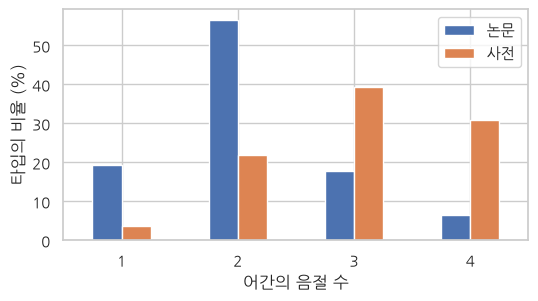

In [19]:
ax = (syl.loc[1:4] * 100).plot.bar(figsize=(6, 3), rot=0)
ax.set_xlabel('어간의 음절 수')
ax.set_ylabel('타입의 비율 (%)')
plt.savefig('plots/stem-syllables.png', dpi=150, bbox_inches='tight')

닫힌 음절로 끝나는 것만 비교한다. 분모는 논문 57개, 사전 2,025개다.

- `fillna(0)`: 논문에 없는 받침('하얗다'의 ㅎ)은 `NaN`이 되므로 0으로 채운다(7강).

표 4의 ㅂ은 64.9%인데 여기서는 63.2%다. 다음 셀에서 살핀다.

In [20]:
pc = p[p['coda'] != ' ']
codas = pd.DataFrame({
    '논문': pc['coda'].value_counts(normalize=True),
    '사전': closed['coda'].value_counts(normalize=True)})
print((codas.loc[['ㅂ', 'ㅄ', 'ㅎ', 'ㅆ']].fillna(0) * 100).round(1))

        논문    사전
coda            
ㅂ     63.2  58.2
ㅄ     12.3   9.1
ㅎ      0.0   8.1
ㅆ      5.3   0.6


| | ㅂ 타입 | ㅂ 비율 | ㅄ 타입 | ㅄ 비율 |
|---|---:|---:|---:|---:|
| 논문 표 4 | 37 | 64.9% | 6 | 10.5% |
| 표 2의 어간을 함수로 나눔 | 36 | 63.2% | 7 | 12.3% |

ㅄ은 발음으로는 [ㅂ]이라(199쪽, 자음군 단순화) 어느 칸에 둘지가 갈릴 수 있는 받침이다. 우리 함수는 글자만 보고 나눈다. 어느 쪽으로 세어도 **ㅂ이 가장 많다**는 것은 같다.

**ㅂ은 원래 많다.** 사전에서 닫힌 음절로 끝나는 형용사 어간의 58.2%가 ㅂ이다. 57개를 아무렇게나 뽑았다면 ㅂ은 57 × 0.582 ≈ 33개쯤이다. 논문에서는 36개(표 4로는 37개)다. 사전의 수가 논문의 둘째 설명을 뒷받침한다. 기대보다 3개쯤 많다. 2음절은 기대보다 21개 많았다. 두 설명은 모두 사전에 대한 말이라 세어 볼 수 있었다. 하나는 사전의 수와 잘 맞고, 다른 하나는 무엇을 기준값으로 삼을지 더 생각하게 한다.

In [21]:
print(pc['coda'].value_counts().to_dict())

{'ㅂ': 36, 'ㅄ': 7, 'ㄶ': 4, 'ㅆ': 3, 'ㅌ': 2, 'ㄺ': 2, 'ㅀ': 1, 'ㄻ': 1, 'ㄹ': 1}


## 이 비교가 말하지 않는 것

- **사전은 쓰이는 말이 아니다.** 사전의 표제어는 드문 말도 자주 쓰는 말도 하나씩 센다. '아니꼽살머리-스럽다'도 '부럽다'도 1이다. 4음절의 대부분인 '-스럽다' 711개 가운데 메신저에서 쓰이는 것은 얼마 되지 않을 것이다.
- **더 나은 기준값.** 메신저 말뭉치에서 어미와 함께 쓰인 형용사를 타입으로 모아 음절 수와 받침을 센다. 어미 없이 쓰인 62개를 그것과 비교하면 '자주 쓰는 말이라 짧다'는 설명과 '짧아서 어미 없이 쓴다'는 설명을 가를 수 있다. 11강의 말뭉치와 10강의 형태소 분석기로 할 수 있는 일이다.
- **버전과 방법.** 이 노트북에는 사전의 버전(`20261012`), 무엇을 '-하다'로 쳤는지, 동모음 탈락을 어떻게 가렸는지가 모두 코드로 남았다. 2,652를 어떻게 얻었는지 누가 물어도 이 노트북을 보여 주면 된다.

## 다음 시간

16강(11월 9일 월요일)은 HuggingFace 데이터 활용이다. 남이 공개해 둔 언어 데이터셋을 HuggingFace Hub에서 찾아 `load_dataset`으로 내려받고, 데이터셋 카드에서 무엇을 모았는지, 어떻게 나누었는지, 라이선스가 무엇인지 읽는다. 오늘 논문과 같은 수를 얻으려면 사전의 버전과 셈의 세부가 필요했다. 남이 만든 데이터셋을 쓰려면 그 데이터셋에 대해 무엇이 적혀 있어야 할까?